In [5]:
import pickle
# 换成你刚才成功读取的路径
file_path = r'C:\Users\13676\Desktop\ml_results.pkl' 

with open(file_path, 'rb') as f:
    ml_data = pickle.load(f)

# 打印里面所有的键名
print(ml_data.keys())

dict_keys(['ml_features', 'feature_name_map', 'X_test', 'y_test', 'X_test_renamed', 'xgb_model', 'lasso_model', 'shap_values'])


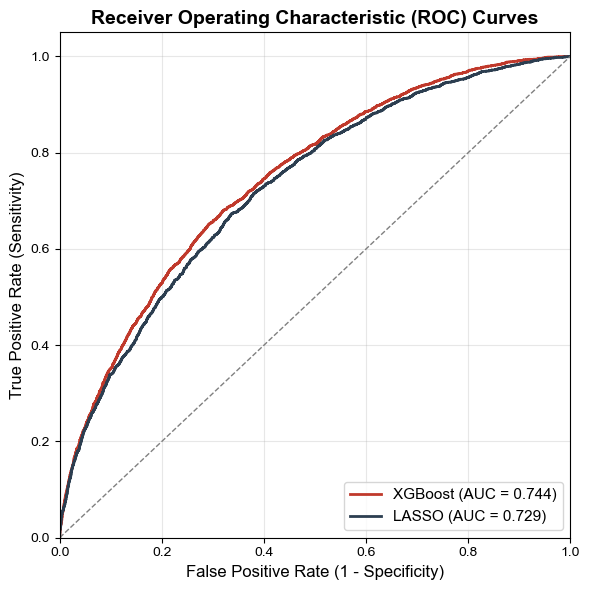

✅ Figure S2 生成完毕！XGBoost AUC: 0.7439, LASSO AUC: 0.7286


In [6]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 设置 Arial 字体
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

# 1. 读取你保存的 pkl 文件
file_path = r'C:\Users\13676\Desktop\ml_results.pkl' 
with open(file_path, 'rb') as f:
    ml_data = pickle.load(f)

xgb_model = ml_data['xgb_model']
lasso_model = ml_data['lasso_model']
X_test = ml_data['X_test']
y_test = ml_data['y_test']

# 2. 为了恢复 LASSO 的标准化，重新读取原始数据（只需要几步）
path = r'C:\Users\13676\Desktop\senna_cohort.csv'
df = pd.read_csv(path, encoding='gb18030', encoding_errors='replace', low_memory=False)
df_main = df.dropna(subset=['senna_exposed', 'hypokalemia_event', 'baseline_k', 'age']).copy()
df_main['y'] = df_main['hypokalemia_event'].astype(int)
df_main['gender_male'] = (df_main['gender'].str.upper().str[0] == 'M').astype(int)

ml_features = ml_data['ml_features']
df_ml = df_main.copy()
df_ml['age_75_84']  = (df_ml['age_group'] == '75-84').astype(int)
df_ml['age_85plus'] = (df_ml['age_group'] == '85+').astype(int)
df_ml = df_ml[ml_features + ['y']].copy()
for c in ml_features:
    df_ml[c] = pd.to_numeric(df_ml[c], errors='coerce')

X = df_ml[ml_features]
y = df_ml['y']
# 保持完全一样的随机种子划分
X_train, _, _, _ = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
# 恢复当时的填充和标准化
train_median = X_train.median()
X_train = X_train.fillna(train_median)
X_test_recovered = X_test.fillna(train_median) # 用 pkl 里的 X_test

scaler = StandardScaler()
scaler.fit(X_train) # 只需在训练集上 fit
X_test_scaled = scaler.transform(X_test_recovered)

# 3. 模型预测
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_prob_lasso = lasso_model.predict_proba(X_test_scaled)[:, 1]

# 4. 计算 ROC 曲线坐标和 AUC
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
auc_xgb = roc_auc_score(y_test, y_prob_xgb)

fpr_lasso, tpr_lasso, _ = roc_curve(y_test, y_prob_lasso)
auc_lasso = roc_auc_score(y_test, y_prob_lasso)

# 5. 开始画图
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr_xgb, tpr_xgb, color='#C0392B', lw=2, label=f'XGBoost (AUC = {auc_xgb:.3f})')
ax.plot(fpr_lasso, tpr_lasso, color='#2C3E50', lw=2, label=f'LASSO (AUC = {auc_lasso:.3f})')
ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=14, fontweight='bold')
ax.legend(loc="lower right", frameon=True, fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Figure_S2_ROC_Curves.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Figure S2 生成完毕！XGBoost AUC: {auc_xgb:.4f}, LASSO AUC: {auc_lasso:.4f}")